## Imports

In [42]:
from xgboost import XGBRegressor  # must be imported BEFORE torch on macOS (libomp clash)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import holidays as holidays_lib
import requests
from typing import Literal, Dict, Tuple
import seaborn as sns
import joblib
from pathlib import Path

# Save trained models to Google Drive, so they survive the Colab runtime and can be downloaded later.
# Falls back to the local 0_my_work/models folder when not running on Colab (e.g. on the Mac).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    MODEL_DIR = Path('/content/drive/MyDrive/gnn-ridership/models')
except Exception as e:                       # not on Colab, or Drive could not be mounted
    print(f"Google Drive not available ({e}) -> saving locally")
    MODEL_DIR = Path("../models")            # 0_my_work/models (one level above this notebook)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("Models will be saved to:", MODEL_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models will be saved to: /content/drive/MyDrive/gnn-ridership/models


In [43]:
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # use the GPU when there is one
print("Using device:", DEVICE)

import random

def set_seed(seed: int = 42) -> None:
    """Make runs reproducible: same weight init, same batch order, same dropout masks."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)             # GPU
    torch.backends.cudnn.deterministic = True    # ask cuDNN for deterministic algorithms
    torch.backends.cudnn.benchmark = False

Using device: cuda


In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

In [45]:
torch.cuda.is_available()

True

In [46]:
pip install fastparquet

## Functions

### Data collection

In [47]:
def _clean_ktm_data(df:pd.DataFrame, year:str) -> pd.DataFrame:
    df = df.copy()

    ## 1. Remove ridership that is negative
    df = df[df['ridership'] > 0]

    ## 2. Remove station that is 'Unknown;
    df = df[df['origin'] != 'Unknown'] 
    df = df[df['destination'] != 'Unknown']

    ## 3. Remove duplicates
    df = df.drop_duplicates()

    ## 4. Remove rows with missing values
    df = df.dropna()
    
    ## 5. Make sure the year is on the specified year
    
    df = df[df['date'].dt.year == int(year)]
    
    ## 6. Retain only operational hour (6AM to 11PM)
    cond = df['datetime'].dt.hour.between(0,5)
    df = df[~cond]
    return df

from functools import lru_cache

@lru_cache(maxsize=None)                     # download each year only once per session
def _download_ktm_data(year: int) -> pd.DataFrame:
    URL_DATA = f'https://storage.data.gov.my/transportation/ktmb/komuter_{year}.parquet'
    return pd.read_parquet(URL_DATA, engine='fastparquet')


def get_clean_ktm_data(year:int)->pd.DataFrame:
    """
    Get Official KTMB data from 'https://storage.data.gov.my/transportation/ktmb/{year}.parquet'
    """
    
    # Read data (cached; .copy() so the cached original is never modified)
    df = _download_ktm_data(year).copy()
    
    # Cast datetime format
    if 'date' in df.columns:
        df['date'] = pd.to_datetime(df['date'])
    
    df['datetime'] = df['date'] + pd.to_timedelta(df['time'] + ':00')
        
    return _clean_ktm_data(df, year)

In [48]:
def get_weather_data(year:int, weather_features: list) -> pd.DataFrame:
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 3.139, "longitude": 101.6869,          # Kuala Lumpur
            "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
            "hourly": ",".join(weather_features),
            "timezone": "Asia/Kuala_Lumpur",
        },
        timeout=60,
    )
    response.raise_for_status()
    df =  pd.DataFrame(response.json()["hourly"]).rename(columns={'time':'datetime'})
    
    df['datetime'] = pd.to_datetime(df['datetime'])

    cond = df['datetime'].dt.hour.between(0,5)
    
    return df[~cond]


def get_temporal_data(year:int)->pd.DataFrame:
    YEAR_HOURS = pd.date_range(f"{year}-01-01", f"{year}-12-31 23:00", freq="h")
    
    ### First-level (base)
    my_holidays = holidays_lib.Malaysia(years=sorted(set(YEAR_HOURS.year)), subdiv="KUL")
    day_of_week = YEAR_HOURS.dayofweek.to_numpy()
    hour = YEAR_HOURS.hour.to_numpy()

    ### Second-levek (derrived from first-level) 
    hour_sin = np.sin(2 * np.pi * hour / 24)
    hour_cos = np.cos(2 * np.pi * hour / 24)
    dow_sin = np.sin(2 * np.pi * day_of_week / 7)
    dow_cos = np.cos(2 * np.pi * day_of_week / 7)
    is_weekend = (day_of_week >= 5).astype(float)
    is_holiday = np.array([d in my_holidays for d in YEAR_HOURS.date], dtype=float)
    
    column_name = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_holiday']
    
    np_stack = np.stack([
        hour_sin, hour_cos, dow_sin, dow_cos, is_weekend, is_holiday,
    ], axis=1)
    
    joined_df = pd.DataFrame(np_stack, columns=column_name, index=YEAR_HOURS).reset_index().rename(columns={'index':'datetime'})
    
    cond = joined_df['datetime'].dt.hour.between(0,5)
    
    return joined_df[~cond] 

### Metrics

In [49]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, mape_threshold: float = 10.0) -> dict:
    """
    All test metrics in one place, in passengers. Used by every model, so they are always computed the same way.

    MAPE is only computed where the true ridership >= mape_threshold: with many near-zero hours
    (quiet stations, early morning), dividing by ~0 would make MAPE explode and tell us nothing.
    """
    y_true = np.asarray(y_true, dtype=np.float64).ravel()   # flatten [S, N, 1] / [S, N] / [S*N] alike
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    err = y_pred - y_true
    mask = y_true >= mape_threshold

    mse = float((err ** 2).mean())
    return {
        "mse":    mse,
        "rmse":   mse ** 0.5,                                                    # typical error, punishes big misses
        "mae":    float(np.abs(err).mean()),                                     # average error in passengers
        "mape_%": float((np.abs(err[mask]) / y_true[mask]).mean() * 100),        # average % error (busy hours only)
        "r2":     float(1 - (err ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()),   # share of variance explained
    }

### Naive

In [50]:
def run_naive(ktm_year: int, lookback: int = 23, train_prop: float = 0.70) -> pd.DataFrame:

    # ---- Same data as run_graph / run_tabular ----
    ktm_df = get_clean_ktm_data(ktm_year)
    STATIONS_LIST = sorted(set(ktm_df['origin']) | set(ktm_df['destination']))
    DATETIME_INDEX = pd.date_range(f"{ktm_year}-01-01", f"{ktm_year}-12-31 23:00", freq="h")
    DATETIME_INDEX = DATETIME_INDEX[DATETIME_INDEX.hour >= 6]
    ktm_np = build_station_series(ktm_df, DATETIME_INDEX, STATIONS_LIST)     # [H, N]

    # ---- Same test hours as the other models ----
    n_samples = len(ktm_np) - lookback                # number of windows
    n_train = int(n_samples * train_prop)
    test_hours = np.arange(n_train, n_samples) + lookback   # hours predicted by the test windows
    train_end = n_train + lookback                    # hours before this are "training data"

    y_true = ktm_np[test_hours]                       # [S_test, N]

    # ---- 1. Persistence ----
    pred_persist = ktm_np[test_hours - 1]

    # ---- 2. Historical average per (station, day-of-week, hour), from TRAIN hours only ----
    how = DATETIME_INDEX.dayofweek * 24 + DATETIME_INDEX.hour            # hour-of-week key
    train_avg = pd.DataFrame(ktm_np[:train_end]).groupby(how[:train_end]).mean()   # [168ish, N]
    pred_histavg = train_avg.reindex(how[test_hours]).to_numpy()

    # ---- Metrics, same format as the other runs ----
    result = []
    for name, y_pred in [("persistence", pred_persist), ("historical_average", pred_histavg)]:
        result.append({"model": name, "variation": "baseline", **compute_metrics(y_true, y_pred)})

    return pd.DataFrame(result)

### Tabular Processing

In [51]:
def make_windows_tabular(
    ktm_np:np.ndarray,
    stations:list,
    datetime_index:pd.DatetimeIndex,
    lookback:int
):
    
    n_hours, n_stations = ktm_np.shape

    lag_cols = [f"lag_{h}" for h in range(lookback, 0, -1)]
    
    frames = []
    for i in range(n_hours - lookback):
        x = ktm_np[i : i + lookback].T
        y = ktm_np[i + lookback]   # [N] next hour, 1D
        
        df = pd.DataFrame(x, columns=lag_cols)
        
        df['station'] = stations
        df['datetime'] = datetime_index[i+lookback]
        df['window'] = i
        df['target'] = y
        
        frames.append(df)

    return pd.concat(frames, ignore_index=True)


In [52]:
def append_feature_tabular(
    ktm_windowed_df:pd.DataFrame,
    feature_dfs:list[pd.DataFrame]
)-> pd.DataFrame:
    
    joined_df = ktm_windowed_df.copy()
    
    for df in feature_dfs:
        joined_df = joined_df.merge(
            df.drop_duplicates(subset='datetime'),
            on='datetime',
            how='left'
        )

    return joined_df

In [53]:
def split_train_valid_test_tabular(
    df:pd.DataFrame,
    train_prop=0.70,  
    test_prop=0.30
):
    
    n_window = df['window'].nunique()
    
    n_train = int(n_window * train_prop)
    
    train_df = df[df['window'] < n_train]
    test_df = df[df['window'] >= n_train]
    
    return train_df, test_df
    

In [54]:
def split_x_y(df):
    drop_cols = ['target', 'datetime', 'window']
    
    x = pd.get_dummies(df.drop(columns=drop_cols), columns=['station'], dtype=float)
    y = df['target']
    
    return x, y 

### Graph Structure

In [55]:
## Core KTM Ridership 

def build_station_series(
    ktm_df:pd.DataFrame,
    datetime_index:pd.DatetimeIndex,
    stations:list
) -> np.ndarray:
    
    """
    Convert KTM tabular data to numpy format.
    """
    
    agg_df = ktm_df.groupby([ktm_df['datetime'].dt.floor('h'), 'origin'])['ridership'].sum()
    
    # Pivot from long format to wide format
    # To fill 0 for stations without ridership at certain datetime
    # whereby other stations have data
    pivot_df = agg_df.unstack(fill_value=0) 
    
    # Reindex based on intialised value upstream (to ensure parity)
    # To fill 0 for stations that never appear as origin
    # or datetime (index) that has no data at all
    pivot_df = pivot_df.reindex(index=datetime_index, columns=stations, fill_value=0)
    
    # Convert to numpy
    numpy_df = pivot_df.to_numpy(dtype=np.float32)
    
    return numpy_df



In [56]:
## Append additional features

def append_feature_graph(
    ridership_np : np.ndarray,
    feature_dfs: list[pd.DataFrame],
    datetime_index : pd.DatetimeIndex
)->np.ndarray:
    
    n_hours, n_stations = ridership_np.shape
    
    # Ridership [H, N] -> [H, N, 1]
    blocks = [ridership_np[:,:,np.newaxis]]
    
    # Pre-process the DF
    for df in feature_dfs:
        # 1. Line up rows with the ridership hours (same order, exactly H rows)
        df = df.drop_duplicates(subset='datetime').set_index('datetime')
        df = df.reindex(datetime_index)
        df = df.interpolate().ffill().bfill()            # fill any missing hours

        # 2. Tabular -> numpy: [H, k]
        values = df.to_numpy(dtype=np.float32)

        # 3. Copy the same values to every station: [H, k] -> [H, 1, k] -> [H, N, k]
        values = values[:, np.newaxis, :]
        values = np.repeat(values, n_stations, axis=1)

        blocks.append(values)
    
    # 4. Glue along the feature axis
    return np.concatenate(blocks, axis=-1)

In [57]:
## Adjacency Matrix

def build_od_flow(ktm_df:pd.DataFrame,
                  STATIONS_LIST:list[str]
) -> np.ndarray :
    """
    Aggregate the daily tabular KTM data
    into a total annual ridership per origin-destination.
    
    Output format is {'origin: destination'}, ridership
    
    """
    
    # Obtain annual ridership for each origin-destination pair
    od_agg_df = ktm_df.groupby(['origin', 'destination'])['ridership'].sum()
    
    # Establish station index dict
    station_idx = {s:i for i, s in enumerate(STATIONS_LIST)}
    
    # Initialise empty numpy array to store the OD ridership
    od_flow = np.zeros((len(STATIONS_LIST), len(STATIONS_LIST)), dtype=np.float32)
    
    for (o,d), ridership in od_agg_df.items():
        od_flow[station_idx[o], station_idx[d]] = ridership
    
    return od_flow + od_flow.T

def build_adjacency_matrix(od_flow:np.ndarray, threshold:int)->np.ndarray:
    """
    Build Origin-Destination (OD) adjacency matrix.

    If the annual sum of an OD exceeds the defined threshold,
    we consider that the stations are connected.
    
    We represent this connection through a matrix of Origin station (row-level)
    to Destination station (column-level).
    
    If the connection is present, we fill an integer 1, else 0.
    """
    
    adj = (od_flow >= threshold).astype(np.float32)
    
    np.fill_diagonal(adj, 0) 

    return adj

def normalize_adjacency_matrix(
    adj_matrix: np.ndarray
)-> np.ndarray:
    """
    A_hat = D^-1/2 (A + I) D^-1/2  (Kipf & Welling GCN normalisation).
    """
    
    a_tilde = adj_matrix + np.eye(len(adj_matrix)) # 1. Add self-loops
    degree = a_tilde.sum(axis=1) # 2. Degree of each station
    d_inv_sqrt = np.diag(1.0 / np.sqrt(degree)) #3. D^-1/2 as a diagonal matrix
    
    return (d_inv_sqrt @ a_tilde @ d_inv_sqrt).astype(np.float32) # 4. Sandwich

In [58]:
def make_windows(series:np.ndarray,
                 lookback:int
) -> tuple[np.ndarray, np.ndarray]:
    xs, ys = [], []
    for i in range(len(series) - lookback):
        xs.append(series[i:i+lookback]) # [T, N, F]  all features
        ys.append(series[i+lookback, :, 0:1]) # [N, 1] ridership only (0:1 keeps the axis)
    
    x = np.stack(xs)
    y = np.stack(ys)
    
    # Add a feature axis which the model expects [S, T, N, F]
    # S: Samples (sliding windows) = n_hours - lookback, 8761 here
    # T: Timesteps per window = lookback (23 hourly snapshots)
    # N: Nodes (number of stations)
    # F: Number of features, 1 for ridership
    
    # x: [S, T, N, F]   y: [S, N, 1]
    return x , y

In [59]:
## Train-test split
def split_train_valid_test(x, y, train_prop=0.70, test_prop=0.30):
    n_samples = len(x)
    n_train = int(n_samples * train_prop)

    x_train, y_train = x[:n_train], y[:n_train]
    x_test, y_test = x[n_train:], y[n_train:]

    return (x_train, y_train), (x_test, y_test)

In [60]:
## Scale data

def scale_data(data, x_mean, x_std, y_mean, y_std):
    x, y = data
    
    x_scaled = (x - x_mean) / x_std
    y_scaled = (y - y_mean) / y_std
    
    return (x_scaled, y_scaled)

In [61]:
def fit(model: nn.Module, 
        optimiser: torch.optim.Optimizer, 
        train_data: tuple[np.ndarray, np.ndarray], 
        valid_data: tuple[np.ndarray, np.ndarray],
        a_hat: np.ndarray,
        n_epoch: int,
        batch_size: int,
        patience: int = 15
) -> dict[str, list[float]]:
    """
    Train with mini-batches. After every epoch, measure the loss on the validation set and
    remember the weights of the BEST epoch. Stop early if validation has not improved for
    `patience` epochs. At the end the model is restored to its best epoch.
    """
    
    # 1 Convert numpy to torch tensors (float32 is the expected format)
    x, y = train_data
    x = torch.tensor(x, dtype=torch.float32) # [S,T,N,F]
    y = torch.tensor(y, dtype=torch.float32) # [S,N,1]
    
    x_val = torch.tensor(valid_data[0], dtype=torch.float32)
    y_val = torch.tensor(valid_data[1], dtype=torch.float32)
    
    # Adjacency Matrix
    a_hat = torch.tensor(a_hat, dtype=torch.float32).to(DEVICE) # [N,N], on GPU if available
    
    n_samples = len(x)
    history = {"train": [], "valid": []}
    best_val, best_state, best_epoch, stale = float("inf"), None, 0, 0
    
    for epoch in range(n_epoch):
        
        # ---- Train one epoch ----
        model.train() # turns dropout ON
        order = torch.randperm(n_samples)
        epoch_loss = 0.0
        
        for start in range(0, n_samples, batch_size):
            idx = order[start: start+batch_size]
            x_batch, y_batch = x[idx].to(DEVICE), y[idx].to(DEVICE)   # move only this batch to the GPU
            
            y_pred = model(x_batch, a_hat)              # Forward pass
            loss = F.mse_loss(y_pred, y_batch)          # Calculate loss

            optimiser.zero_grad() # Clear the previous batch's gradients, since PyTorch adds them up by default
            loss.backward()       # dLoss/dWeight for every weight, stores in param.grad
            optimiser.step()      # weight = weight - learning_rate * grad
            
            epoch_loss += loss.item() * len(idx) # weight by batch size (last batch may be smaller)

        # ---- Validation loss (no training, dropout OFF) ----
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for start in range(0, len(x_val), 256):
                xb, yb = x_val[start:start+256].to(DEVICE), y_val[start:start+256].to(DEVICE)
                val_loss += F.mse_loss(model(xb, a_hat), yb).item() * len(xb)
        val_loss /= len(x_val)
        
        history["train"].append(epoch_loss / n_samples)
        history["valid"].append(val_loss)
        
        # ---- Keep the best epoch ----
        if val_loss < best_val:
            best_val, best_epoch, stale = val_loss, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}   # copy of the weights
            marker = "  * best"
        else:
            stale += 1
            marker = ""
        
        print(f"Epoch {epoch} of {n_epoch}: train {history['train'][-1]:.4f} | valid {val_loss:.4f}{marker}")
        
        if stale >= patience:
            print(f"Early stop: validation has not improved for {patience} epochs")
            break
    
    model.load_state_dict(best_state)   # restore the best epoch's weights
    print(f"Restored best epoch {best_epoch} (valid loss {best_val:.4f})")
    
    return history

### Modelling

In [62]:
class DenseGCNLayer(nn.Module):
    """One GCN layer, dense form: A_hat @ X @ W + b (bias added after aggregation).

    Expects a pre-normalised adjacency (see data.normalize_adjacency). A_hat
    broadcasts over any leading dimensions, so x may be [N, F], [B, N, F] or
    [B, T, N, F] — the same layer serves every timestep of every sample at once.
    """

    def __init__(self, in_features: int, out_features: int) -> None:
        super().__init__()
        self.linear = nn.Linear(in_features, out_features, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_features))

    def forward(self, x: torch.Tensor, a_hat: torch.Tensor) -> torch.Tensor:
        return a_hat @ self.linear(x) + self.bias


class STGNN(nn.Module):
    def __init__(self,
                 in_features: int,
                 hidden_dim: int,
                 num_gcn_layers:int,
                 horizon:int,
                 dropout:float,
                 n_stations:int = 0,
                 emb_dim:int = 0          # 0 = no station embedding (the original model)
                )->None:
        super().__init__()
        
        # Station embedding: a small LEARNED vector per station (its "profile"),
        # appended to the input features so the model knows WHICH station it is looking at.
        self.emb_dim = emb_dim
        if emb_dim > 0:
            self.station_emb = nn.Embedding(n_stations, emb_dim)    # table: N rows x emb_dim numbers
        
        dims = [in_features + emb_dim] + [hidden_dim] * num_gcn_layers
        
        self.gcn_layers = nn.ModuleList(
            DenseGCNLayer(dims[i], dims[i+1]) for i in range(num_gcn_layers)
        ) # Spatial Layer
        
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True) # Temporal Layer
        self.head = nn.Linear(hidden_dim, horizon) # Final output layer
        self.dropout = dropout
    
    def forward(self, x:torch.Tensor, a_hat: torch.Tensor)-> torch.Tensor:
        if self.emb_dim > 0:
            b, t, n, _ = x.shape
            emb = self.station_emb.weight.expand(b, t, n, self.emb_dim)   # same vector at every sample + hour
            x = torch.cat([x, emb], dim=-1)                               # [B,T,N,F] -> [B,T,N,F+emb_dim]
        
        h = x
        
        for layer in self.gcn_layers:
            h = F.relu(layer(h, a_hat))
            h = F.dropout(h, self.dropout, self.training)
        
        b, t, n, d = h.shape # b (batch size, timestep, nodes-stations) # temporal: GRU per station
        seq = h.permute(0,2,1,3).reshape(b*n, t, d)
        _, last_hidden = self.gru(seq)
        
        return self.head(last_hidden.squeeze(0)).view(b, n, -1)

### Run

In [63]:
def run_graph(ktm_year: int,
        model_variation: Literal['M1', 'M2', 'M3'],
        lookback: int = 23,
        n_epoch: int = 20,
        batch_size: int = 50,
        patience: int = 15,
        seed: int = 42,
        hidden_dim: int = 64,
        lr: float = 1e-3,
        emb_dim: int = 0,
        num_gcn_layers: int = 2,
        dropout: float = 0.2,
        run_name: str | None = None,         # file name in MODEL_DIR (default: stgnn_{variation}_seed{seed})
        save_test_data: bool = True          # False = smaller file, but no feature importance possible
        )->Tuple[Dict[str, list], pd.DataFrame]:

    set_seed(seed)                            # same starting point for every run -> reproducible

    # ---- KTM Ridership Data ----
    ktm_df = get_clean_ktm_data(ktm_year)
    STATIONS_LIST = sorted(set(ktm_df['origin']) | set(ktm_df['destination']))
    DATETIME_INDEX = pd.date_range(f"{ktm_year}-01-01", f"{ktm_year}-12-31 23:00", freq="h")
    DATETIME_INDEX = DATETIME_INDEX[DATETIME_INDEX.hour >= 6]                 # operating hours only
    ktm_np = build_station_series(ktm_df, DATETIME_INDEX, STATIONS_LIST)     # [H, N]

    # ---- Additional Features ----
    if model_variation == 'M1':
        feature_dfs = []
    elif model_variation == 'M2':
        feature_dfs = [get_temporal_data(ktm_year)]
    elif model_variation == 'M3':
        weather_features = ['temperature_2m', 'relative_humidity_2m', 'precipitation']
        feature_dfs = [get_temporal_data(ktm_year),
                       get_weather_data(year=ktm_year, weather_features=weather_features)]

    feature_np = append_feature_graph(ktm_np, feature_dfs, DATETIME_INDEX)        # [H, N, F]
    print(f"{model_variation}: feature_np shape = {feature_np.shape}")

    # ---- Adjacency Matrix ----
    od_flow = build_od_flow(ktm_df, STATIONS_LIST)
    adj_matrix = normalize_adjacency_matrix(build_adjacency_matrix(od_flow, 5_000))

    # ---- Windows -> Train-valid-test split -> Standardisation ----
    x_all, y_all = make_windows(feature_np, lookback)
    train_data, test_data = split_train_valid_test(x_all, y_all)

    # Validation = the last 15% of the TRAIN windows (test set is untouched)
    x_tr, y_tr = train_data
    n_val = int(len(x_tr) * 0.15)
    fit_data   = (x_tr[:-n_val], y_tr[:-n_val])       # used to update the weights
    valid_data = (x_tr[-n_val:], y_tr[-n_val:])       # used only to pick the best epoch

    x_train, _ = fit_data                      # scaling stats from the fitting part only
    x_mean = x_train.mean(axis=(0, 1, 2))      # one mean per feature, shape [F]
    x_std  = x_train.std(axis=(0, 1, 2))       # one std per feature,  shape [F]
    x_std[x_std == 0] = 1.0                    # guard against a constant feature
    y_mean, y_std = x_mean[0], x_std[0]        # y is ridership = feature 0

    train_scaled = scale_data(fit_data,   x_mean, x_std, y_mean, y_std)
    valid_scaled = scale_data(valid_data, x_mean, x_std, y_mean, y_std)
    test_scaled  = scale_data(test_data,  x_mean, x_std, y_mean, y_std)

    # ---- Fit Model ----
    config = dict(in_features=feature_np.shape[-1],     # 1 for M1, 7 for M2, 10 for M3
                  hidden_dim=hidden_dim, num_gcn_layers=num_gcn_layers, horizon=1, dropout=dropout,
                  n_stations=len(STATIONS_LIST), emb_dim=emb_dim)
    model = STGNN(**config).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    history = fit(model=model,
                  optimiser=opt,
                  train_data=train_scaled,
                  valid_data=valid_scaled,
                  a_hat=adj_matrix,
                  n_epoch=n_epoch,
                  batch_size=batch_size,
                  patience=patience)

    # ---- Evaluate on test (in passengers) ----
    model.eval()                                          # turns dropout OFF
    a_hat_t = torch.tensor(adj_matrix, dtype=torch.float32).to(DEVICE)
    x_test_t = torch.tensor(test_scaled[0], dtype=torch.float32)
    preds = []
    with torch.no_grad():                                 # no gradients needed for prediction
        for start in range(0, len(x_test_t), 256):        # in chunks, to save memory
            preds.append(model(x_test_t[start:start+256].to(DEVICE), a_hat_t).cpu().numpy())   # back to CPU for numpy
    y_pred = np.concatenate(preds) * y_std + y_mean       # unscale -> passengers
    y_true = test_data[1]                                 # already in passengers

    metrics = {
        "model": "stgnn", 
        "variation": model_variation, 
        "seed": seed,
        "hidden_dim": hidden_dim,
        "lr": lr,
        "emb_dim": emb_dim,
        "best_valid": min(history["valid"]),                       # what hyperparameters are picked on
        "best_epoch": int(np.argmin(history["valid"])),
        "epochs_run": len(history["valid"]),
        **compute_metrics(y_true, y_pred)
    }
    
    print(metrics)

    # ---- Save to disk (everything needed to reload + compute feature importance) ----
    feature_names = ['ridership'] + [c for df in feature_dfs for c in df.columns if c != 'datetime']
    if run_name is None:
        run_name = f"stgnn_{model_variation}_seed{seed}"
    torch.save({
        "state_dict": model.state_dict(),                   # the trained weights (best epoch)
        "config": config,                                   # everything needed to rebuild the model
        "lr": lr,
        "metrics": metrics,
        "a_hat": adj_matrix,
        "x_test": test_scaled[0] if save_test_data else None,   # scaled test inputs  [S, T, N, F]
        "y_test": test_data[1] if save_test_data else None,     # test targets in passengers [S, N, 1]
        "y_mean": y_mean, "y_std": y_std,
        "feature_names": feature_names,                     # name of each F index
        "stations": STATIONS_LIST,
        "history": history,
    }, MODEL_DIR / f"{run_name}.pt")

    return history, pd.DataFrame([metrics])   # same format as run_tabular

In [64]:
def run_tabular(
    ktm_year:int,
    model_variation: Literal['M1','M2','M3'],
    lookback:int,
    seed:int = 42,
)->pd.DataFrame:

    set_seed(seed)
    
    # ---- KTM Ridership Data ----
    ktm_df = get_clean_ktm_data(ktm_year)
    STATIONS_LIST = sorted(set(ktm_df['origin']) | set(ktm_df['destination']))
    DATETIME_INDEX = pd.date_range(f"{ktm_year}-01-01", f"{ktm_year}-12-31 23:00", freq="h")
    DATETIME_INDEX = DATETIME_INDEX[DATETIME_INDEX.hour >= 6]                 # operating hours only
    ktm_np = build_station_series(ktm_df, DATETIME_INDEX, STATIONS_LIST)     # [H, N]   
    
    ## Make windows for ktm ridership, in dataframe format
    ktm_windowed_df = make_windows_tabular(ktm_np=ktm_np, stations=STATIONS_LIST,
                                           datetime_index=DATETIME_INDEX, lookback=lookback)
    
     # ---- Additional Features ----
    if model_variation == 'M1':
        feature_dfs = []
    elif model_variation == 'M2':
        feature_dfs = [get_temporal_data(ktm_year)]
    elif model_variation == 'M3':
        weather_features = ['temperature_2m', 'relative_humidity_2m', 'precipitation']
        feature_dfs = [get_temporal_data(ktm_year), get_weather_data(weather_features=weather_features, year=ktm_year)]
    
    
    ## Join and merge if external features present
    final_df = append_feature_tabular(ktm_windowed_df, feature_dfs)
    
    ## Split train-validate-test
    train_data, test_data = split_train_valid_test_tabular(final_df)
    
    ## Split X and Y
    
    x_train, y_train = split_x_y(train_data)
    x_test, y_test = split_x_y(test_data)
    
    ## Scale
    scaler = StandardScaler()
    x_train_s = scaler.fit_transform(x_train)   # fit on train ONLY
    x_test_s  = scaler.transform(x_test)
        
    ## Fit model
    models_dict = {
        "linear_regression" : LinearRegression(),
        "random_forest_regressor": RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=seed),
        "xbg": XGBRegressor(random_state=seed)
    }
    
    # Test data + scaler, shared by all models of this variation
    joblib.dump({
        "scaler": scaler,
        "feature_names": list(x_train.columns),
        "x_test": x_test_s,                                # scaled test inputs
        "y_test": y_test.to_numpy(),                       # test targets in passengers
    }, MODEL_DIR / f"tabular_data_{model_variation}.joblib")

    result = []
    
    for i, (name, model) in enumerate(models_dict.items()):

        
        print(f"Training for {name.upper()} - Model Number:{i+1}/{len(models_dict.keys())}")
        
        model.fit(x_train_s, y_train)
        
        joblib.dump(model, MODEL_DIR / f"{name}_{model_variation}.joblib")   # save trained model

        y_pred = model.predict(x_test_s)
        result.append({
            "model": name,
            "variation": model_variation,
            **compute_metrics(y_test.to_numpy(), y_pred)
        })
    
    return pd.DataFrame(result)

In [65]:
## Load saved models from disk (no retraining needed)

def load_stgnn(model_variation: str = None, seed: int = 42, run_name: str | None = None):
    if run_name is None:
        run_name = f"stgnn_{model_variation}_seed{seed}"
    # weights_only=False: the file also holds numpy arrays and lists (our own file, so safe)
    bundle = torch.load(MODEL_DIR / f"{run_name}.pt", weights_only=False,
                        map_location="cpu")     # loads on any machine, even if trained on GPU
    model = STGNN(**bundle["config"])                 # rebuild the same architecture
    model.load_state_dict(bundle["state_dict"])       # put the trained weights back in
    model.to(DEVICE).eval()
    return model, bundle


def load_tabular(model_name: str, model_variation: str):
    model = joblib.load(MODEL_DIR / f"{model_name}_{model_variation}.joblib")
    data = joblib.load(MODEL_DIR / f"tabular_data_{model_variation}.joblib")
    return model, data


def rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(((y_true - y_pred) ** 2).mean()))


def predict_stgnn(model, x_test, a_hat, y_mean, y_std) -> np.ndarray:
    """Predict in chunks (to save memory) and unscale back to passengers."""
    a = torch.tensor(a_hat, dtype=torch.float32).to(DEVICE)
    x = torch.tensor(x_test, dtype=torch.float32)
    preds = []
    with torch.no_grad():
        for start in range(0, len(x), 256):
            preds.append(model(x[start:start+256].to(DEVICE), a).cpu().numpy())
    return np.concatenate(preds) * y_std + y_mean


def evaluate_saved_tabular(model_variation: str, model_names: list[str]) -> pd.DataFrame:
    """Recompute test metrics from saved tabular models (no data download, no training)."""
    result = []
    for name in model_names:
        model, data = load_tabular(name, model_variation)
        y_pred = model.predict(data['x_test'])
        result.append({"model": name, "variation": model_variation, **compute_metrics(data['y_test'], y_pred)})
    return pd.DataFrame(result)


def evaluate_saved_stgnn(model_variation: str = None, seed: int = 42,
                         run_name: str | None = None) -> Tuple[Dict[str, list], pd.DataFrame]:
    """Metrics of a saved STGNN without retraining. Returns (history, metrics_df) like run_graph."""
    model, b = load_stgnn(model_variation, seed, run_name)
    
    if b.get('metrics') is not None:                  # newer files store the full metrics dict
        metrics = dict(b['metrics'])
    else:                                             # older files: basic info only
        metrics = {"model": "stgnn", "variation": model_variation, "seed": seed}
    
    if b.get('x_test') is not None:                   # test data saved -> recompute (and verify) RMSE
        y_pred = predict_stgnn(model, b['x_test'], b['a_hat'], b['y_mean'], b['y_std'])
        metrics.update(compute_metrics(b['y_test'], y_pred))
    print(metrics)
    return b['history'], pd.DataFrame([metrics])

## [1] Data Collection and Cleaning

### 1.1 KTM Data

In [26]:
ktm_2024_df = get_clean_ktm_data(2024)

In [27]:
ktm_2024_df

,date,time,origin,destination,ridership,datetime
511,2024-01-01,06:00,KL Sentral,Batang Benar,30,2024-01-01 06:00:00
512,2024-01-01,06:00,Seremban,Kajang,2,2024-01-01 06:00:00
513,2024-01-01,06:00,Seremban,KL Sentral,6,2024-01-01 06:00:00
514,2024-01-01,06:00,KL Sentral,Tanjong Malim,5,2024-01-01 06:00:00
515,2024-01-01,06:00,Seremban,Batu Caves,12,2024-01-01 06:00:00
...,...,...,...,...,...,...
2686103,2024-12-31,23:00,Midvalley,Sungai Gadut,1,2024-12-31 23:00:00
2686104,2024-12-31,23:00,Subang Jaya,Padang Jawa,8,2024-12-31 23:00:00
2686105,2024-12-31,23:00,Abdullah Hukum,Padang Jawa,1,2024-12-31 23:00:00
2686106,2024-12-31,23:00,KL Sentral,Padang Jawa,6,2024-12-31 23:00:00


In [28]:
## Derrive the stations and index in the beginning

STATIONS_LIST = sorted(set(ktm_2024_df['origin']) | set(ktm_2024_df['destination']))
DT_INDEX = pd.date_range("2024-01-01", "2024-12-31 23:00", freq="h")
DT_INDEX = DT_INDEX[DT_INDEX.hour >= 6]

### 1.2 Weather Data

In [29]:
weather_features = [
    'temperature_2m',
    'relative_humidity_2m',
    'precipitation'
]

weather_df = get_weather_data(year=2024, weather_features=weather_features)

In [30]:
weather_df

,datetime,temperature_2m,relative_humidity_2m,precipitation
6,2024-01-01 06:00:00,24.3,98,0.0
7,2024-01-01 07:00:00,24.5,96,0.0
8,2024-01-01 08:00:00,24.8,94,0.0
9,2024-01-01 09:00:00,26.0,91,0.0
10,2024-01-01 10:00:00,27.4,83,0.0
...,...,...,...,...
8779,2024-12-31 19:00:00,26.1,88,0.1
8780,2024-12-31 20:00:00,25.7,93,0.0
8781,2024-12-31 21:00:00,25.9,95,0.2
8782,2024-12-31 22:00:00,25.5,96,1.0


### 1.3 Temporal Data

In [31]:
temporal_df = get_temporal_data(2024)

In [32]:
temporal_df

,datetime,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,is_holiday
6,2024-01-01 06:00:00,1.000000,6.123234e-17,0.000000,1.00000,0.0,1.0
7,2024-01-01 07:00:00,0.965926,-2.588190e-01,0.000000,1.00000,0.0,1.0
8,2024-01-01 08:00:00,0.866025,-5.000000e-01,0.000000,1.00000,0.0,1.0
9,2024-01-01 09:00:00,0.707107,-7.071068e-01,0.000000,1.00000,0.0,1.0
10,2024-01-01 10:00:00,0.500000,-8.660254e-01,0.000000,1.00000,0.0,1.0
...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,-0.965926,2.588190e-01,0.781831,0.62349,0.0,0.0
8780,2024-12-31 20:00:00,-0.866025,5.000000e-01,0.781831,0.62349,0.0,0.0
8781,2024-12-31 21:00:00,-0.707107,7.071068e-01,0.781831,0.62349,0.0,0.0
8782,2024-12-31 22:00:00,-0.500000,8.660254e-01,0.781831,0.62349,0.0,0.0


## [2] Run

### Naive - Baseline

In [66]:
naive_df = run_naive(ktm_year=2024)

In [67]:
naive_df

,model,variation,mse,rmse,mae,mape_%,r2
0,persistence,baseline,1693.854052,41.156458,16.273954,57.660323,0.655966
1,historical_average,baseline,417.542434,20.433855,8.475633,31.984809,0.915194


### Tabular - Traditional ML

In [ ]:
mv_list = ['M1', 'M2', 'M3']
TABULAR_MODEL_NAMES = ['linear_regression', 'random_forest_regressor', 'xbg']   # keys of models_dict in run_tabular

tabular_all_df = []

for mv in mv_list:
    saved_files = [MODEL_DIR / f"{name}_{mv}.joblib" for name in TABULAR_MODEL_NAMES] \
                + [MODEL_DIR / f"tabular_data_{mv}.joblib"]

    if all(f.exists() for f in saved_files):              # everything saved -> just load
        print(f"{mv}: loading saved tabular models")
        tabular_single_df = evaluate_saved_tabular(mv, TABULAR_MODEL_NAMES)
    else:                                                 # something missing -> train fresh
        print(f"{mv}: saved models not found -> training")
        tabular_single_df = run_tabular(
            ktm_year=2024,
            model_variation=mv,
            lookback=23
        )

    tabular_all_df.append(tabular_single_df)

tabular_all_df = pd.concat(tabular_all_df)
tabular_all_df

M1: loading saved tabular models


/usr/lib/python3.13/pickle.py:1754: UserWarning: [14:19:48] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


M2: loading saved tabular models
M3: loading saved tabular models


,model,variation,mse,rmse
0,linear_regression,M1,668.703184,25.859296
1,random_forest_regressor,M1,385.842883,19.642884
2,xbg,M1,425.322807,20.623356
0,linear_regression,M2,663.397048,25.756495
1,random_forest_regressor,M2,291.130124,17.062536
2,xbg,M2,306.865677,17.517582
0,linear_regression,M3,663.316925,25.754940
1,random_forest_regressor,M3,292.088838,17.090607
2,xbg,M3,306.165892,17.497597


### Numpy - GNN

In [68]:
import itertools, json

# ---- Training settings shared by every STGNN run ----
N_EPOCH    = 300        # upper limit; early stopping restores the best epoch
PATIENCE   = 20         # stop after 20 epochs without validation improvement
BATCH_SIZE = 64
mv_list    = ['M1', 'M2', 'M3']

#### Step 1: Hyperparameter search (on validation loss, never test)
Every combination in `HP_GRID` is trained on **one variation (M2) and one seed**. The combination with the lowest
**validation** loss wins and is saved to `best_hparams.json`; the same settings are then used for M1, M2 and M3 so the
ablation stays fair. Runs that already exist in `MODEL_DIR` are loaded instead of retrained.

In [69]:
HP_GRID = {
    "hidden_dim": [64, 128],
    "lr":         [1e-3, 5e-4],
    "emb_dim":    [0, 8],          # 0 = no station embedding, 8 = learned 8-number profile per station
}
HP_SEARCH_VARIATION = 'M2'
HP_SEARCH_SEED = 42

search_rows = []
for hidden_dim, lr, emb_dim in itertools.product(*HP_GRID.values()):
    run_name = f"hpsearch_{HP_SEARCH_VARIATION}_h{hidden_dim}_lr{lr}_emb{emb_dim}"

    if (MODEL_DIR / f"{run_name}.pt").exists():                 # already trained -> load
        print(f"{run_name}: loading saved run")
        _, df = evaluate_saved_stgnn(run_name=run_name)
    else:                                                       # missing -> train
        print(f"{run_name}: training")
        _, df = run_graph(ktm_year=2024, model_variation=HP_SEARCH_VARIATION, lookback=23,
                          n_epoch=N_EPOCH, batch_size=BATCH_SIZE, patience=PATIENCE, seed=HP_SEARCH_SEED,
                          hidden_dim=hidden_dim, lr=lr, emb_dim=emb_dim,
                          run_name=run_name, save_test_data=False)   # small files: not needed for importance
    search_rows.append(df)

hp_search_df = pd.concat(search_rows, ignore_index=True).sort_values('best_valid')
hp_search_df.to_csv(MODEL_DIR / "hp_search_results.csv", index=False)

# ---- Pick the best combination by VALIDATION loss and save it ----
best = hp_search_df.iloc[0]
BEST_HPARAMS = {"hidden_dim": int(best['hidden_dim']), "lr": float(best['lr']), "emb_dim": int(best['emb_dim'])}
(MODEL_DIR / "best_hparams.json").write_text(json.dumps(BEST_HPARAMS, indent=2))

print("Best hyperparameters (by validation loss):", BEST_HPARAMS)
hp_search_df[['hidden_dim', 'lr', 'emb_dim', 'best_valid', 'best_epoch', 'epochs_run', 'rmse']]

hpsearch_M2_h64_lr0.001_emb0: training
M2: feature_np shape = (6588, 58, 7)
Epoch 0 of 300: train 0.7807 | valid 0.4856  * best
Epoch 1 of 300: train 0.4868 | valid 0.4047  * best
Epoch 2 of 300: train 0.4343 | valid 0.3310  * best
Epoch 3 of 300: train 0.3862 | valid 0.2978  * best
Epoch 4 of 300: train 0.3520 | valid 0.2766  * best
Epoch 5 of 300: train 0.3321 | valid 0.2540  * best
Epoch 6 of 300: train 0.3147 | valid 0.2256  * best
Epoch 7 of 300: train 0.2844 | valid 0.2095  * best
Epoch 8 of 300: train 0.2707 | valid 0.1988  * best
Epoch 9 of 300: train 0.2552 | valid 0.1892  * best
Epoch 10 of 300: train 0.2449 | valid 0.2017
Epoch 11 of 300: train 0.2434 | valid 0.1661  * best
Epoch 12 of 300: train 0.2283 | valid 0.1709
Epoch 13 of 300: train 0.2237 | valid 0.2691
Epoch 14 of 300: train 0.2411 | valid 0.1688
Epoch 15 of 300: train 0.2116 | valid 0.1869
Epoch 16 of 300: train 0.2182 | valid 0.1581  * best
Epoch 17 of 300: train 0.2032 | valid 0.1475  * best
Epoch 18 of 300: tra

,hidden_dim,lr,emb_dim,best_valid,best_epoch,epochs_run,rmse
7,128,0.0005,8,0.038899,210,231,16.725731
1,64,0.0010,8,0.039006,264,285,16.742810
3,64,0.0005,8,0.042339,296,300,16.982113
5,128,0.0010,8,0.043684,91,112,17.218513
4,128,0.0010,0,0.044487,269,290,18.630684
6,128,0.0005,0,0.053448,287,300,19.467923
0,64,0.0010,0,0.057447,292,300,21.568941
2,64,0.0005,0,0.067809,298,300,21.072986


#### Step 2: Final runs = 5 seeds x 3 variations, with the best hyperparameters
Each (variation, seed) is saved as `stgnn_final_{variation}_seed{seed}.pt` and loaded if it already exists.
Results are written to `final_graph_results.csv` after every run, so a Colab disconnect loses nothing.
Only the first seed keeps the (large) test data, which feature importance uses.

In [70]:
SEEDS = [0, 1, 2, 3, 4]

history_all = {}
graph_rows = []

for seed in SEEDS:
    for mv in mv_list:
        run_name = f"stgnn_final_{mv}_seed{seed}"

        if (MODEL_DIR / f"{run_name}.pt").exists():             # saved -> just load
            print(f"{run_name}: loading saved run")
            history, df = evaluate_saved_stgnn(run_name=run_name)
        else:                                                   # missing -> train fresh
            print(f"{run_name}: training")
            history, df = run_graph(ktm_year=2024, model_variation=mv, lookback=23,
                                    n_epoch=N_EPOCH, batch_size=BATCH_SIZE, patience=PATIENCE, seed=seed,
                                    run_name=run_name, save_test_data=(seed == SEEDS[0]),
                                    **BEST_HPARAMS)

        graph_rows.append(df)
        history_all[(mv, seed)] = history
        pd.concat(graph_rows, ignore_index=True).to_csv(MODEL_DIR / "final_graph_results.csv", index=False)

graph_runs_df = pd.concat(graph_rows, ignore_index=True)        # one row per (variation, seed)

# One row per variation (mean over seeds), same format as the tabular results
graph_all_df = (graph_runs_df.groupby('variation', as_index=False)[['mse', 'rmse', 'mae', 'mape_%', 'r2']].mean()
                .assign(model='stgnn'))
graph_all_df

stgnn_final_M1_seed0: training
M1: feature_np shape = (6588, 58, 1)
Epoch 0 of 300: train 0.7310 | valid 0.4722  * best
Epoch 1 of 300: train 0.4894 | valid 0.4074  * best
Epoch 2 of 300: train 0.4320 | valid 0.3551  * best
Epoch 3 of 300: train 0.3828 | valid 0.3276  * best
Epoch 4 of 300: train 0.3365 | valid 0.2783  * best
Epoch 5 of 300: train 0.3235 | valid 0.3127
Epoch 6 of 300: train 0.2994 | valid 0.2620  * best
Epoch 7 of 300: train 0.2995 | valid 0.2381  * best
Epoch 8 of 300: train 0.2627 | valid 0.2195  * best
Epoch 9 of 300: train 0.2454 | valid 0.2001  * best
Epoch 10 of 300: train 0.2225 | valid 0.1794  * best
Epoch 11 of 300: train 0.2127 | valid 0.1730  * best
Epoch 12 of 300: train 0.1948 | valid 0.1622  * best
Epoch 13 of 300: train 0.1846 | valid 0.1791
Epoch 14 of 300: train 0.1813 | valid 0.1452  * best
Epoch 15 of 300: train 0.1667 | valid 0.1580
Epoch 16 of 300: train 0.1574 | valid 0.1360  * best
Epoch 17 of 300: train 0.1597 | valid 0.2382
Epoch 18 of 300: tra

: 

### All Results

In [ ]:
results_df = pd.concat([naive_df, tabular_all_df, graph_all_df], ignore_index=True)
results_df.sort_values(['variation', 'rmse'])

,model,variation,mse,rmse,seed
3,random_forest_regressor,M1,385.842883,19.642884,NaN
4,xbg,M1,425.322807,20.623356,NaN
11,stgnn,M1,645.240598,25.401587,42.0
2,linear_regression,M1,668.703184,25.859296,NaN
6,random_forest_regressor,M2,291.130124,17.062536,NaN
7,xbg,M2,306.865677,17.517582,NaN
12,stgnn,M2,498.005132,22.316029,42.0
5,linear_regression,M2,663.397048,25.756495,NaN
9,random_forest_regressor,M3,292.088838,17.090607,NaN
10,xbg,M3,306.165892,17.497597,NaN


In [ ]:
results_df.to_csv(MODEL_DIR / "overall_results_2024.csv")

## [3] Analysis

### 3.1 Ablation study
How much does RMSE change when temporal features are added (M1 → M2) and when weather is added (M2 → M3)?
**Negative Δ = the features helped** (lower error); positive Δ = they hurt.

Caveat: the STGNN row comes from a single seed, so a Δ of a few tenths can be noise. Confirm with 3–5 seeds before claiming it in the thesis.

In [ ]:
ablation_df = (
    results_df[results_df['variation'] != 'baseline']        # naive baselines have no M1/M2/M3
    .pivot_table(index='model', columns='variation', values='rmse')
)

ablation_df['Δ M1→M2 (temporal)'] = ablation_df['M2'] - ablation_df['M1']
ablation_df['Δ M2→M3 (weather)']  = ablation_df['M3'] - ablation_df['M2']

ablation_df.round(2)

variation,M1,M2,M3,Δ M1→M2 (temporal),Δ M2→M3 (weather)
model,,,,,
linear_regression,25.86,25.76,25.75,-0.10,-0.00
random_forest_regressor,19.64,17.06,17.09,-2.58,0.03
stgnn,25.40,22.32,21.74,-3.09,-0.57
xbg,20.62,17.52,17.50,-3.11,-0.02


#### STGNN across seeds (mean ± std, and paired deltas)
The table above uses the **mean** over seeds for the STGNN. Below: how much the STGNN varies between seeds, and the
M1→M2 / M2→M3 change **within the same seed** (same random start, so less noisy). If all seeds agree on the sign of a
delta, the effect is real rather than noise.

In [ ]:
seed_summary = graph_runs_df.groupby('variation')['rmse'].agg(['mean', 'std', 'min', 'max'])
seed_summary.round(2)

In [ ]:
paired = graph_runs_df.pivot(index='seed', columns='variation', values='rmse')
paired['Δ M1→M2 (temporal)'] = paired['M2'] - paired['M1']
paired['Δ M2→M3 (weather)']  = paired['M3'] - paired['M2']

print("Mean Δ:", paired[['Δ M1→M2 (temporal)', 'Δ M2→M3 (weather)']].mean().round(3).to_dict())
paired.round(2)

### 3.2 Feature importance (permutation, M3 only)
Take a trained model + its test set, **shuffle one feature** across test samples (breaking its link to the target) and re-measure RMSE.
The RMSE increase (in passengers) = how much the model relies on that feature. Repeated `n_repeats` times and averaged.

Only M3 is used, since it is the only variation that has every feature. Models are loaded from disk (`models/`), so no retraining is needed.

In [ ]:
def permutation_importance_stgnn(model_variation: str = 'M3',
                                 n_repeats: int = 3,
                                 seed: int = 42,
                                 run_name: str | None = None) -> pd.DataFrame:
    model, b = load_stgnn(model_variation, run_name=run_name)
    rng = np.random.default_rng(seed)
    x_test, y_test = b['x_test'], b['y_test']               # x_test: [S, T, N, F]

    base = rmse(y_test, predict_stgnn(model, x_test, b['a_hat'], b['y_mean'], b['y_std']))

    rows = []
    for f, name in enumerate(b['feature_names']):
        increases = []
        for _ in range(n_repeats):
            x_perm = x_test.copy()
            perm = rng.permutation(len(x_test))              # random sample order
            x_perm[..., f] = x_test[perm, :, :, f]           # shuffle ONLY feature f
            y_pred = predict_stgnn(model, x_perm, b['a_hat'], b['y_mean'], b['y_std'])
            increases.append(rmse(y_test, y_pred) - base)

        rows.append({"model": "stgnn", "feature": name, "rmse_increase": float(np.mean(increases))})
        print(f"stgnn | {name}: +{rows[-1]['rmse_increase']:.3f}")

    return pd.DataFrame(rows)

In [ ]:
def permutation_importance_tabular(model_name: str,
                                   model_variation: str = 'M3',
                                   n_repeats: int = 3,
                                   seed: int = 42) -> pd.DataFrame:
    model, d = load_tabular(model_name, model_variation)
    rng = np.random.default_rng(seed)
    x_test, y_test, cols = d['x_test'], d['y_test'], d['feature_names']

    # Group columns: all 23 lags -> "ridership" (comparable with the STGNN's single ridership feature),
    # all one-hot station_* -> "station" (shuffled together, so each row keeps exactly one station),
    # every other column on its own.
    groups = {"ridership": [i for i, c in enumerate(cols) if c.startswith('lag_')],
              "station":   [i for i, c in enumerate(cols) if c.startswith('station_')]}
    for i, c in enumerate(cols):
        if not c.startswith(('lag_', 'station_')):
            groups[c] = [i]

    base = rmse(y_test, model.predict(x_test))

    rows = []
    for name, idx in groups.items():
        increases = []
        for _ in range(n_repeats):
            x_perm = x_test.copy()
            perm = rng.permutation(len(x_test))
            x_perm[:, idx] = x_test[perm][:, idx]            # shuffle the whole group together
            increases.append(rmse(y_test, model.predict(x_perm)) - base)

        rows.append({"model": model_name, "feature": name, "rmse_increase": float(np.mean(increases))})
        print(f"{model_name} | {name}: +{rows[-1]['rmse_increase']:.3f}")

    return pd.DataFrame(rows)

In [ ]:
importance_df = pd.concat([
    permutation_importance_stgnn('M3', run_name=f"stgnn_final_M3_seed{SEEDS[0]}"),   # final model (seed with test data saved)
    permutation_importance_tabular('xbg', 'M3'),
    permutation_importance_tabular('random_forest_regressor', 'M3'),
], ignore_index=True)

stgnn | ridership: +23.798
stgnn | hour_sin: +33.797
stgnn | hour_cos: +39.977
stgnn | dow_sin: +3.854
stgnn | dow_cos: +0.748
stgnn | is_weekend: +7.893
stgnn | is_holiday: +1.233
stgnn | temperature_2m: +0.893
stgnn | relative_humidity_2m: +0.739
stgnn | precipitation: +0.047
xbg | ridership: +74.281
xbg | station: +1.849
xbg | hour_sin: +9.485
xbg | hour_cos: +6.944
xbg | dow_sin: +8.537
xbg | dow_cos: +0.808
xbg | is_weekend: +0.000
xbg | is_holiday: +0.913
xbg | temperature_2m: +0.129
xbg | relative_humidity_2m: +0.196
xbg | precipitation: +-0.011
random_forest_regressor | ridership: +78.435
random_forest_regressor | station: +0.860
random_forest_regressor | hour_sin: +6.249
random_forest_regressor | hour_cos: +2.823
random_forest_regressor | dow_sin: +4.443
random_forest_regressor | dow_cos: +0.663
random_forest_regressor | is_weekend: +1.036
random_forest_regressor | is_holiday: +0.496
random_forest_regressor | temperature_2m: +0.019
random_forest_regressor | relative_humidity_2

**How to read it:** `+5.0` = shuffling that feature made predictions 5 passengers worse (RMSE) → heavily relied on. `≈ 0` = ignored. Slightly negative = noise (treat as 0).
If different model families rank features the same way, the finding is about the **data**, not one model (strongest evidence for RO3).
The STGNN has no `station` row: it identifies stations through the graph instead.

In [ ]:
importance_table = (
    importance_df
    .pivot(index='feature', columns='model', values='rmse_increase')
    .sort_values('stgnn', ascending=False)
)

importance_table.round(2)

model,random_forest_regressor,stgnn,xbg
feature,,,
hour_cos,2.82,39.98,6.94
hour_sin,6.25,33.80,9.48
ridership,78.43,23.80,74.28
is_weekend,1.04,7.89,0.00
dow_sin,4.44,3.85,8.54
is_holiday,0.50,1.23,0.91
temperature_2m,0.02,0.89,0.13
dow_cos,0.66,0.75,0.81
relative_humidity_2m,0.00,0.74,0.20


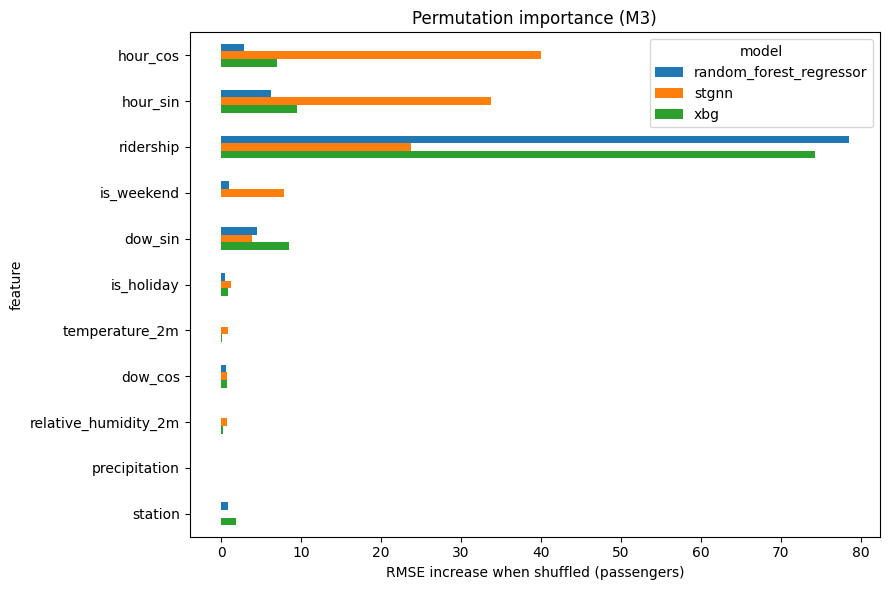

In [ ]:
importance_table.plot.barh(figsize=(9, 6))
plt.gca().invert_yaxis()                                     # most important on top
plt.xlabel("RMSE increase when shuffled (passengers)")
plt.title("Permutation importance (M3)")
plt.tight_layout()
plt.show()